In [15]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns 

In [16]:
df = pd.read_csv("../Data/customer_booking.csv" ,encoding='latin-1')
df.head(10)

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0
5,1,Internet,RoundTrip,3,48,20,Thu,AKLDEL,New Zealand,1,0,1,5.52,0
6,3,Internet,RoundTrip,201,33,6,Thu,AKLDEL,New Zealand,1,0,1,5.52,0
7,2,Internet,RoundTrip,238,19,14,Mon,AKLDEL,India,1,0,1,5.52,0
8,1,Internet,RoundTrip,80,22,4,Mon,AKLDEL,New Zealand,0,0,1,5.52,0
9,1,Mobile,RoundTrip,378,30,12,Sun,AKLDEL,India,0,0,0,5.52,0


In [17]:
df.shape
df.columns.tolist()

['num_passengers',
 'sales_channel',
 'trip_type',
 'purchase_lead',
 'length_of_stay',
 'flight_hour',
 'flight_day',
 'route',
 'booking_origin',
 'wants_extra_baggage',
 'wants_preferred_seat',
 'wants_in_flight_meals',
 'flight_duration',
 'booking_complete']

In [18]:
#missing values
df.isnull().sum()


#data types
df.dtypes

# duplicate values
df.duplicated().sum()

np.int64(719)

In [19]:
# check target column is blanced
df['booking_complete'].describe()
print(df['booking_complete'].value_counts())



booking_complete
0    42522
1     7478
Name: count, dtype: int64


In [20]:
df['flight_day'].unique()

<StringArray>
['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri']
Length: 7, dtype: str

In [21]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [22]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5])

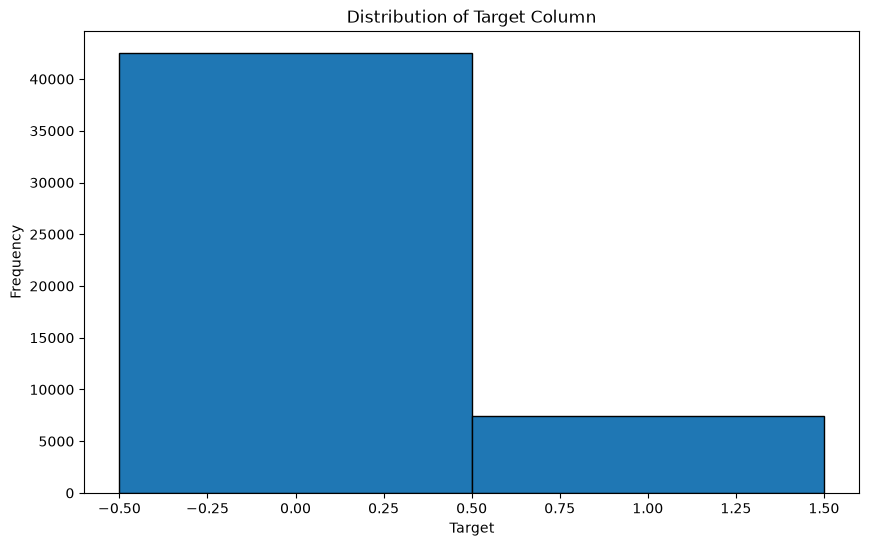

In [23]:
# visualization of the target column
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['booking_complete'], bins=[-0.5, 0.5, 1.5], edgecolor='black')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.title('Distribution of Target Column')
plt.show()

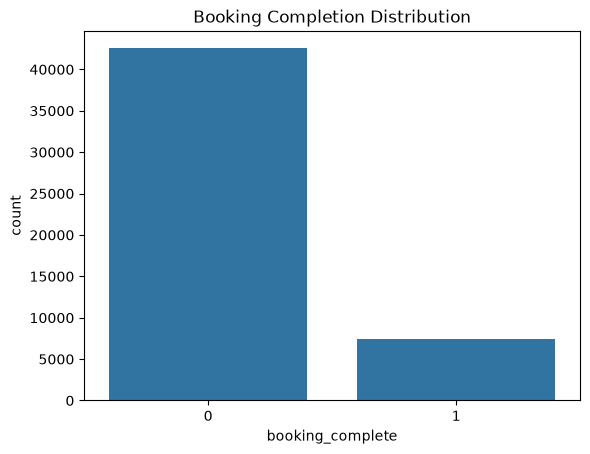

In [24]:
sns.countplot(x='booking_complete', data=df)
plt.title("Booking Completion Distribution")
plt.show()


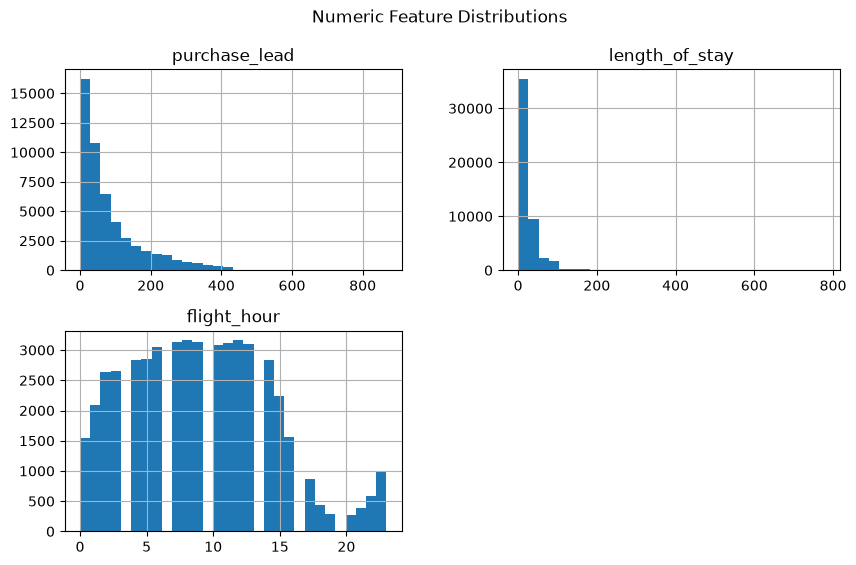

In [25]:
num_features = ['purchase_lead', 'length_of_stay', 'flight_hour']
df[num_features].hist(bins=30, figsize=(10,6))
plt.suptitle("Numeric Feature Distributions")
plt.show()


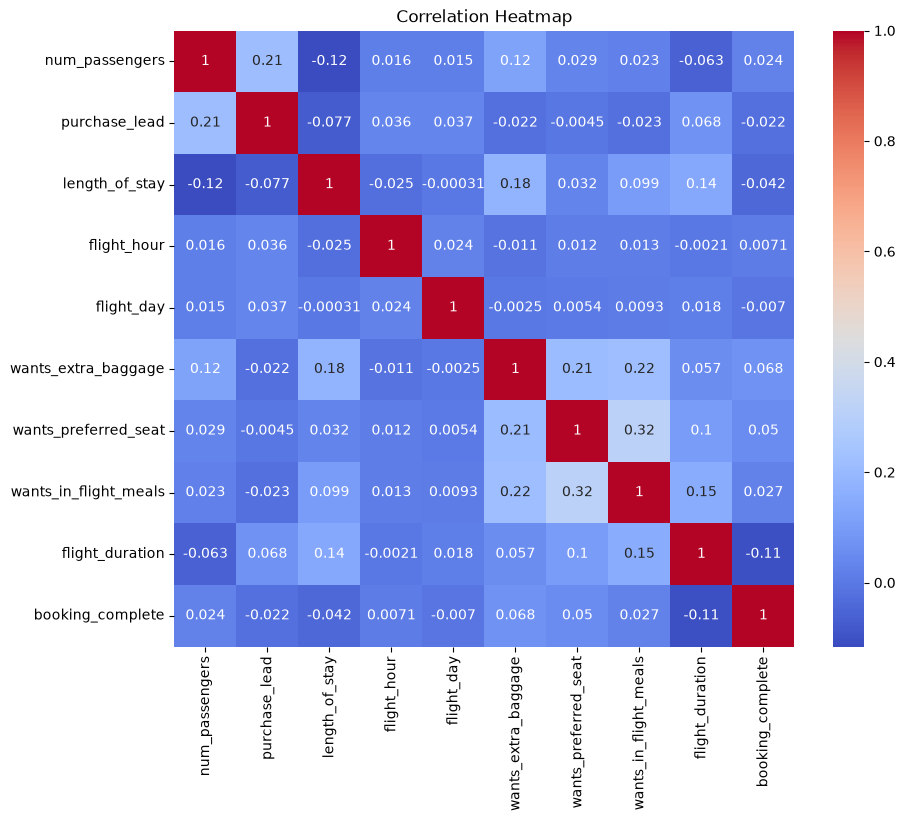

In [27]:
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


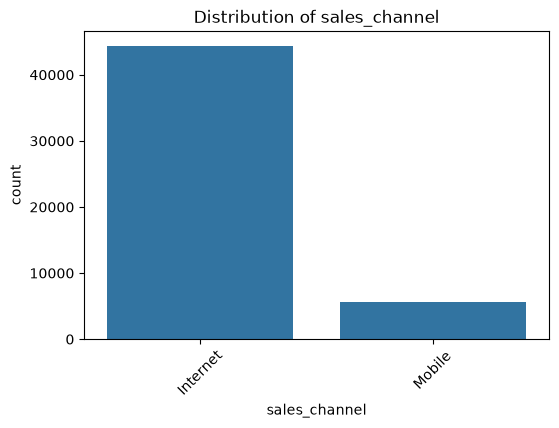

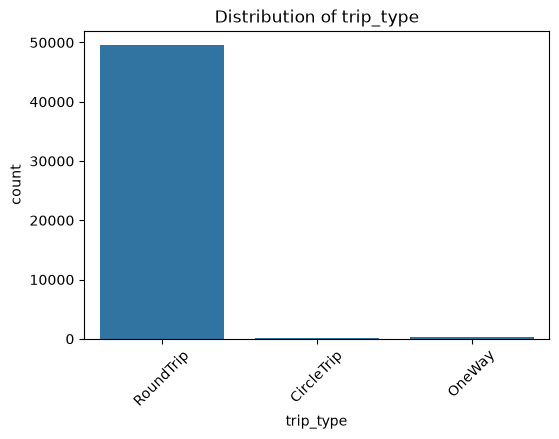

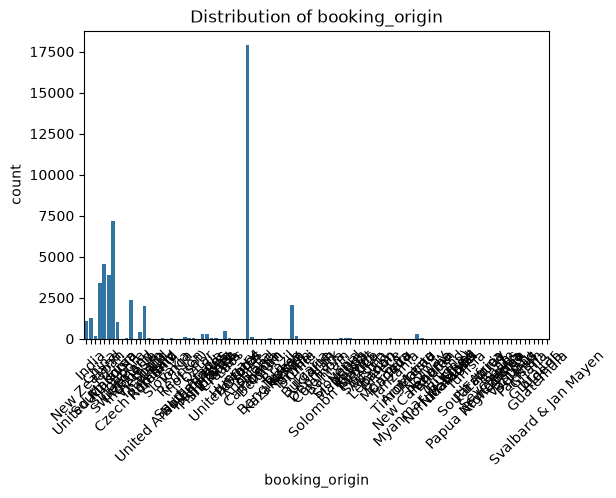

In [28]:
cat_features = ['sales_channel', 'trip_type', 'booking_origin']
for col in cat_features:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()


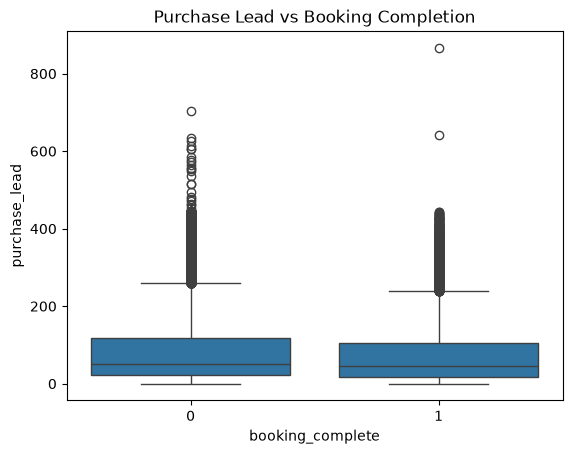

In [29]:
sns.boxplot(x='booking_complete', y='purchase_lead', data=df)
plt.title("Purchase Lead vs Booking Completion")
plt.show()


In [ ]:
#model 
    
# Train Random Forest
from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
